# GP vs BNN Response-Shape Metric

Compare two small-data surrogate strategies on the BCLF response-shape metric:

- GP: fit a scalar GP directly on the true `BCLFResponseShapeOptimizationSpec` metric.
- BNN: fit the legacy response surrogate on S11/S21 dB curves, predict test responses, then compute the same response-shape metric from predicted responses.

Lower metric is better. The top-k analysis asks whether the cases selected by the predicted metric have low true metrics.


In [1]:
from __future__ import annotations

import csv
import json
import math
import sys
import time
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    import torch
except ImportError:  # pragma: no cover - notebook environment guard
    torch = None


def find_project_root(start: Path) -> Path:
    candidates = [start.resolve(), *start.resolve().parents, Path('/home/zhanghf/projects/vector')]
    for candidate in candidates:
        if (candidate / 'src' / 'optimization').exists() and (candidate / 'src' / 'modeling').exists():
            return candidate
    raise RuntimeError(f'Cannot locate project root from cwd={start.resolve()}')


PROJECT_ROOT = find_project_root(Path.cwd())
SRC = PROJECT_ROOT / 'src'
for path in (PROJECT_ROOT, SRC):
    path_str = str(path)
    if path_str in sys.path:
        sys.path.remove(path_str)
    sys.path.insert(0, path_str)

from modeling import BCLFTouchstoneDatasetLoader, LegacyBNNResponseSurrogate
from optimization.optimization_spec import BCLFResponseShapeOptimizationSpec

print('project_root:', PROJECT_ROOT)


project_root: /home/zhanghf/projects/vector


## Settings

`RUN_EXPERIMENT=False` keeps the notebook safe to open and validate. Use `EXPERIMENT_MODE='smoke'` for a quick end-to-end check, then switch to `'full'` for the requested 5 seeds x 4 train sizes campaign.


In [2]:
RUN_EXPERIMENT = True
EXPERIMENT_MODE = 'full'  # 'smoke' or 'full'

SEEDS_FULL = [0, 1, 2, 3, 4]
TRAIN_SIZES_FULL = [10, 20, 30, 40]
TOPK_VALUES = [5, 10]

DATASET_DIR = PROJECT_ROOT / 'data' / 'bandpass_coupled_line_filter_export' / 'ext'
OUTPUT_DIR = PROJECT_ROOT / 'experiments' / 'gp_vs_bnn_response_shape_metric'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BNN_CHECKPOINT_DIR = OUTPUT_DIR / 'bnn_checkpoints'
BNN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BNN_USE_CHECKPOINTS = True
BNN_FORCE_RETRAIN = False
BNN_CONTINUE_LEARNING = True
BNN_UPDATE_EPOCHS_FULL = 200
BNN_UPDATE_EPOCHS_SMOKE = 1

SPEC_KWARGS = {
    'passband_ghz': (4.8, 5.4),
    'lower_stopband_ghz': (3.6, 4.4),
    'upper_stopband_ghz': (5.8, 8.7),
    'min_passband_s21_db': -5.0,
    'max_passband_s11_db': -7.0,
    'max_stopband_s21_db': -15.0,
}

BNN_KWARGS_FULL = {
    'hidden_dims': [256, 256, 256],
    'epochs': 800,
    'batch_size': 1024,
    'lr': 1e-3,
    'bayesian_loss_weight': 1e-4,
    'mc_samples': 50,
    'target_mode': 'db',
    'device': None if torch is None else ('cuda' if torch.cuda.is_available() else 'cpu'),
}

if EXPERIMENT_MODE == 'smoke':
    SEEDS = [0]
    TRAIN_SIZES = [10]
    BNN_KWARGS = dict(BNN_KWARGS_FULL, hidden_dims=[16], epochs=1, batch_size=64, mc_samples=2)
    BNN_UPDATE_EPOCHS = BNN_UPDATE_EPOCHS_SMOKE
else:
    SEEDS = list(SEEDS_FULL)
    TRAIN_SIZES = list(TRAIN_SIZES_FULL)
    BNN_KWARGS = dict(BNN_KWARGS_FULL)
    BNN_UPDATE_EPOCHS = BNN_UPDATE_EPOCHS_FULL

CONFIG = {
    'experiment_mode': EXPERIMENT_MODE,
    'seeds': SEEDS,
    'train_sizes': TRAIN_SIZES,
    'topk_values': TOPK_VALUES,
    'dataset_dir': str(DATASET_DIR),
    'output_dir': str(OUTPUT_DIR),
    'bnn_checkpoint_dir': str(BNN_CHECKPOINT_DIR),
    'bnn_use_checkpoints': BNN_USE_CHECKPOINTS,
    'bnn_force_retrain': BNN_FORCE_RETRAIN,
    'bnn_continue_learning': BNN_CONTINUE_LEARNING,
    'bnn_update_epochs': BNN_UPDATE_EPOCHS,
    'spec_kwargs': SPEC_KWARGS,
    'bnn_kwargs': BNN_KWARGS,
}

print(json.dumps(CONFIG, indent=2, default=str))


{
  "experiment_mode": "full",
  "seeds": [
    0,
    1,
    2,
    3,
    4
  ],
  "train_sizes": [
    10,
    20,
    30,
    40
  ],
  "topk_values": [
    5,
    10
  ],
  "dataset_dir": "/home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext",
  "output_dir": "/home/zhanghf/projects/vector/experiments/gp_vs_bnn_response_shape_metric",
  "bnn_checkpoint_dir": "/home/zhanghf/projects/vector/experiments/gp_vs_bnn_response_shape_metric/bnn_checkpoints",
  "bnn_use_checkpoints": true,
  "bnn_force_retrain": false,
  "bnn_continue_learning": true,
  "bnn_update_epochs": 200,
  "spec_kwargs": {
    "passband_ghz": [
      4.8,
      5.4
    ],
    "lower_stopband_ghz": [
      3.6,
      4.4
    ],
    "upper_stopband_ghz": [
      5.8,
      8.7
    ],
    "min_passband_s21_db": -5.0,
    "max_passband_s11_db": -7.0,
    "max_stopband_s21_db": -15.0
  },
  "bnn_kwargs": {
    "hidden_dims": [
      256,
      256,
      256
    ],
    "epochs": 800,
    "batch_size

## Load Dataset And True Response-Shape Metric

In [3]:
dataset = BCLFTouchstoneDatasetLoader(dataset_dir=DATASET_DIR).load()
spec = BCLFResponseShapeOptimizationSpec(**SPEC_KWARGS)

X_all = np.asarray(dataset.X, dtype=float)
case_ids = list(dataset.case_ids)
y_true = np.asarray(
    [spec.evaluate(dataset.freqs, dataset.s_params[i]).scalar_objective() for i in range(dataset.n_samples)],
    dtype=float,
)

X_MIN = X_all.min(axis=0)
X_MAX = X_all.max(axis=0)
X_SPAN = np.where(np.abs(X_MAX - X_MIN) < 1e-12, 1.0, X_MAX - X_MIN)

print('samples:', dataset.n_samples)
print('variables:', dataset.variable_order)
print('freq_points:', dataset.n_freqs)
print('response-shape metric range:', float(np.min(y_true)), float(np.median(y_true)), float(np.max(y_true)))


samples: 347
variables: ['L', 'L1', 'L2', 'W', 'W1', 'W2', 'S1', 'S2']
freq_points: 401
response-shape metric range: 0.19594439741006234 14.03600950882385 49.0929724514509


## Helpers

In [4]:
def bounds_normalize(X: np.ndarray) -> np.ndarray:
    X = np.asarray(X, dtype=float)
    return np.clip((X - X_MIN) / X_SPAN, 0.0, 1.0)


def make_split(seed: int, train_size: int) -> tuple[np.ndarray, np.ndarray]:
    if train_size <= 0 or train_size >= dataset.n_samples:
        raise ValueError('train_size must be between 1 and n_samples - 1')
    rng = np.random.default_rng(int(seed))
    order = rng.permutation(np.arange(dataset.n_samples, dtype=int))
    train_idx = np.asarray(order[:train_size], dtype=int)
    test_idx = np.asarray(order[train_size:], dtype=int)
    validate_split(train_idx, test_idx)
    return train_idx, test_idx


def validate_split(train_idx: np.ndarray, test_idx: np.ndarray) -> None:
    train_set = set(np.asarray(train_idx, dtype=int).tolist())
    test_set = set(np.asarray(test_idx, dtype=int).tolist())
    if train_set & test_set:
        raise AssertionError('train/test split overlap detected')
    if len(train_set) + len(test_set) != dataset.n_samples:
        raise AssertionError('train/test split does not cover the full dataset')


def mae(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.mean(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))


def rmse(a: np.ndarray, b: np.ndarray) -> float:
    diff = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    return float(np.sqrt(np.mean(diff ** 2)))


def rankdata(values: np.ndarray) -> np.ndarray:
    order = np.argsort(np.asarray(values, dtype=float))
    ranks = np.empty(len(order), dtype=float)
    ranks[order] = np.arange(len(order), dtype=float)
    return ranks


def spearman(a: np.ndarray, b: np.ndarray) -> float:
    if len(a) < 2:
        return float('nan')
    ra = rankdata(np.asarray(a, dtype=float))
    rb = rankdata(np.asarray(b, dtype=float))
    if np.std(ra) < 1e-12 or np.std(rb) < 1e-12:
        return float('nan')
    return float(np.corrcoef(ra, rb)[0, 1])


def topk_recall(true_metric: np.ndarray, pred_metric: np.ndarray, k: int) -> float:
    k_eff = min(int(k), len(true_metric))
    if k_eff <= 0:
        return float('nan')
    true_top = set(np.argsort(true_metric)[:k_eff].tolist())
    pred_top = set(np.argsort(pred_metric)[:k_eff].tolist())
    return float(len(true_top & pred_top) / k_eff)


def evaluate_predicted_sparams(indices: np.ndarray, pred_sparams: np.ndarray) -> np.ndarray:
    if len(indices) != len(pred_sparams):
        raise ValueError('predicted response count must match index count')
    return np.asarray(
        [spec.evaluate(dataset.freqs, pred_sparams[pos]).scalar_objective() for pos in range(len(indices))],
        dtype=float,
    )


def fit_gp_predict(train_idx: np.ndarray, test_idx: np.ndarray, seed: int) -> tuple[np.ndarray, float, float]:
    from botorch.fit import fit_gpytorch_mll
    from botorch.models import SingleTaskGP
    from botorch.models.transforms import Standardize
    from gpytorch.mlls import ExactMarginalLogLikelihood
    import torch as torch_lib

    device = torch_lib.device('cuda') if torch_lib.cuda.is_available() else torch_lib.device('cpu')
    dtype = torch_lib.double
    torch_lib.manual_seed(int(seed))
    if device.type == 'cuda':
        torch_lib.cuda.manual_seed_all(int(seed))

    X_train = torch_lib.tensor(bounds_normalize(X_all[train_idx]), dtype=dtype, device=device)
    y_train = torch_lib.tensor(y_true[train_idx].reshape(-1, 1), dtype=dtype, device=device)
    X_test = torch_lib.tensor(bounds_normalize(X_all[test_idx]), dtype=dtype, device=device)

    fit_start = time.perf_counter()
    model = SingleTaskGP(X_train, y_train, outcome_transform=Standardize(m=1))
    mll = ExactMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll)
    fit_seconds = time.perf_counter() - fit_start

    predict_start = time.perf_counter()
    model.eval()
    with torch_lib.no_grad():
        posterior = model.posterior(X_test)
        pred = posterior.mean.detach().cpu().numpy().reshape(-1)
    predict_seconds = time.perf_counter() - predict_start
    return pred, fit_seconds, predict_seconds


def bnn_checkpoint_path(seed: int, train_size: int) -> Path:
    return BNN_CHECKPOINT_DIR / f'legacy_bnn_response_seed{int(seed)}_n{int(train_size)}.pt'


def find_previous_bnn_checkpoint(seed: int, train_size: int) -> tuple[int, Path] | None:
    previous_sizes = [int(size) for size in sorted(TRAIN_SIZES) if int(size) < int(train_size)]
    for previous_size in reversed(previous_sizes):
        path = bnn_checkpoint_path(seed, previous_size)
        if path.exists():
            return previous_size, path
    return None


def train_or_load_bnn_model(seed: int, train_size: int, train_idx: np.ndarray) -> tuple[LegacyBNNResponseSurrogate, float, dict[str, Any]]:
    checkpoint_path = bnn_checkpoint_path(seed, train_size)
    device = BNN_KWARGS.get('device')
    start = time.perf_counter()

    if BNN_USE_CHECKPOINTS and checkpoint_path.exists() and not BNN_FORCE_RETRAIN:
        model = LegacyBNNResponseSurrogate.load(checkpoint_path, device=device)
        fit_seconds = time.perf_counter() - start
        return model, fit_seconds, {
            'fit_mode': 'loaded_checkpoint',
            'checkpoint_path': str(checkpoint_path),
            'source_checkpoint_path': str(checkpoint_path),
            'source_train_size': int(train_size),
            'update_epochs': 0,
            'trained_epochs': int(model.trained_epochs),
        }

    previous = find_previous_bnn_checkpoint(seed, train_size) if BNN_USE_CHECKPOINTS and BNN_CONTINUE_LEARNING and not BNN_FORCE_RETRAIN else None
    if previous is not None:
        previous_size, previous_path = previous
        model = LegacyBNNResponseSurrogate.load(previous_path, device=device)
        model.update(dataset, train_idx, epochs=int(BNN_UPDATE_EPOCHS))
        fit_mode = 'continued_from_checkpoint'
        source_checkpoint_path = str(previous_path)
        source_train_size = int(previous_size)
        update_epochs = int(BNN_UPDATE_EPOCHS)
    else:
        model = LegacyBNNResponseSurrogate(seed=int(seed), **BNN_KWARGS)
        model.fit(dataset, train_idx)
        fit_mode = 'fit_from_scratch'
        source_checkpoint_path = None
        source_train_size = None
        update_epochs = 0

    fit_seconds = time.perf_counter() - start
    if BNN_USE_CHECKPOINTS:
        model.save(
            checkpoint_path,
            metadata={
                'seed': int(seed),
                'train_size': int(train_size),
                'train_indices': np.asarray(train_idx, dtype=int).tolist(),
                'fit_mode': fit_mode,
                'source_checkpoint_path': source_checkpoint_path,
                'source_train_size': source_train_size,
                'update_epochs': update_epochs,
                'experiment': 'gp_vs_bnn_response_shape_metric',
            },
        )
    return model, fit_seconds, {
        'fit_mode': fit_mode,
        'checkpoint_path': str(checkpoint_path) if BNN_USE_CHECKPOINTS else None,
        'source_checkpoint_path': source_checkpoint_path,
        'source_train_size': source_train_size,
        'update_epochs': int(update_epochs),
        'trained_epochs': int(model.trained_epochs),
    }


def fit_bnn_predict_metric(train_idx: np.ndarray, test_idx: np.ndarray, seed: int, train_size: int) -> tuple[np.ndarray, float, float, dict[str, Any]]:
    model, fit_seconds, runtime_info = train_or_load_bnn_model(seed, train_size, train_idx)

    predict_start = time.perf_counter()
    pred_sparams = model.predict_s_params(dataset, test_idx, mc_samples=BNN_KWARGS.get('mc_samples'))
    pred_metric = evaluate_predicted_sparams(test_idx, pred_sparams)
    predict_seconds = time.perf_counter() - predict_start
    return pred_metric, fit_seconds, predict_seconds, runtime_info


def prediction_rows_for_method(method: str, seed: int, train_size: int, test_idx: np.ndarray, pred_metric: np.ndarray, fit_seconds: float, predict_seconds: float, runtime_info: dict[str, Any] | None = None) -> list[dict[str, Any]]:
    if len(test_idx) != len(pred_metric):
        raise AssertionError(f'{method} prediction length mismatch')
    if not np.all(np.isfinite(pred_metric)):
        raise AssertionError(f'{method} produced non-finite predictions')
    runtime_info = dict(runtime_info or {})
    rows = []
    for idx, pred in zip(test_idx, pred_metric):
        true_value = float(y_true[int(idx)])
        rows.append({
            'seed': int(seed),
            'train_size': int(train_size),
            'method': method,
            'dataset_index': int(idx),
            'case_id': case_ids[int(idx)],
            'true_metric': true_value,
            'pred_metric': float(pred),
            'abs_error': float(abs(true_value - float(pred))),
            'fit_seconds': float(fit_seconds),
            'predict_seconds': float(predict_seconds),
            'fit_mode': runtime_info.get('fit_mode'),
            'checkpoint_path': runtime_info.get('checkpoint_path'),
            'source_checkpoint_path': runtime_info.get('source_checkpoint_path'),
            'source_train_size': runtime_info.get('source_train_size'),
            'update_epochs': runtime_info.get('update_epochs'),
            'trained_epochs': runtime_info.get('trained_epochs'),
        })
    return rows


def summarize_predictions(rows: list[dict[str, Any]]) -> dict[str, Any]:
    true_metric = np.asarray([row['true_metric'] for row in rows], dtype=float)
    pred_metric = np.asarray([row['pred_metric'] for row in rows], dtype=float)
    first = rows[0]
    return {
        'seed': int(first['seed']),
        'train_size': int(first['train_size']),
        'method': first['method'],
        'n_test': int(len(rows)),
        'metric_mae': mae(true_metric, pred_metric),
        'metric_rmse': rmse(true_metric, pred_metric),
        'metric_spearman': spearman(true_metric, pred_metric),
        'top5_recall': topk_recall(true_metric, pred_metric, 5),
        'top10_recall': topk_recall(true_metric, pred_metric, 10),
        'fit_seconds': float(first['fit_seconds']),
        'predict_seconds': float(first['predict_seconds']),
        'fit_mode': first.get('fit_mode'),
        'checkpoint_path': first.get('checkpoint_path'),
        'source_checkpoint_path': first.get('source_checkpoint_path'),
        'source_train_size': first.get('source_train_size'),
        'update_epochs': first.get('update_epochs'),
        'trained_epochs': first.get('trained_epochs'),
    }


def topk_rows_and_summary(rows: list[dict[str, Any]], k_values: list[int]) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    ordered = sorted(rows, key=lambda row: float(row['pred_metric']))
    selection_rows = []
    summary_rows = []
    first = rows[0]
    for k in k_values:
        k_eff = min(int(k), len(ordered))
        selected = ordered[:k_eff]
        true_values = np.asarray([row['true_metric'] for row in selected], dtype=float)
        for rank, row in enumerate(selected, start=1):
            selection_rows.append({
                'seed': int(first['seed']),
                'train_size': int(first['train_size']),
                'method': first['method'],
                'k': int(k),
                'k_eff': int(k_eff),
                'pred_rank': int(rank),
                'dataset_index': int(row['dataset_index']),
                'case_id': row['case_id'],
                'true_metric': float(row['true_metric']),
                'pred_metric': float(row['pred_metric']),
            })
        summary_rows.append({
            'seed': int(first['seed']),
            'train_size': int(first['train_size']),
            'method': first['method'],
            'k': int(k),
            'k_eff': int(k_eff),
            'true_metric_mean': float(np.mean(true_values)),
            'true_metric_min': float(np.min(true_values)),
        })
    return selection_rows, summary_rows


## Run Experiment

In [5]:
prediction_rows: list[dict[str, Any]] = []
summary_rows: list[dict[str, Any]] = []
topk_selection_rows: list[dict[str, Any]] = []
topk_summary_rows: list[dict[str, Any]] = []

if not RUN_EXPERIMENT:
    print('RUN_EXPERIMENT=False; skipping training and prediction.')
else:
    (OUTPUT_DIR / 'config.json').write_text(json.dumps(CONFIG, indent=2, default=str), encoding='utf-8')
    for seed in SEEDS:
        for train_size in TRAIN_SIZES:
            train_idx, test_idx = make_split(seed, train_size)
            print(f'seed={seed} train_size={train_size} n_test={len(test_idx)}')

            method_predictions = {}
            gp_pred, gp_fit_seconds, gp_predict_seconds = fit_gp_predict(train_idx, test_idx, seed)
            method_predictions['gp_direct_metric'] = (gp_pred, gp_fit_seconds, gp_predict_seconds, {'fit_mode': 'fit_from_scratch'})

            bnn_pred, bnn_fit_seconds, bnn_predict_seconds, bnn_runtime = fit_bnn_predict_metric(train_idx, test_idx, seed, train_size)
            method_predictions['bnn_response_metric'] = (bnn_pred, bnn_fit_seconds, bnn_predict_seconds, bnn_runtime)

            for method, (pred_metric, fit_seconds, predict_seconds, runtime_info) in method_predictions.items():
                rows = prediction_rows_for_method(method, seed, train_size, test_idx, pred_metric, fit_seconds, predict_seconds, runtime_info)
                prediction_rows.extend(rows)
                summary_rows.append(summarize_predictions(rows))
                selected_rows, selected_summary = topk_rows_and_summary(rows, TOPK_VALUES)
                topk_selection_rows.extend(selected_rows)
                topk_summary_rows.extend(selected_summary)

    prediction_df = pd.DataFrame(prediction_rows)
    summary_df = pd.DataFrame(summary_rows)
    topk_selection_df = pd.DataFrame(topk_selection_rows)
    topk_summary_df = pd.DataFrame(topk_summary_rows)

    prediction_df.to_csv(OUTPUT_DIR / 'prediction_rows.csv', index=False)
    summary_df.to_csv(OUTPUT_DIR / 'summary_by_seed_size_method.csv', index=False)
    topk_selection_df.to_csv(OUTPUT_DIR / 'topk_selection_rows.csv', index=False)
    topk_summary_df.to_csv(OUTPUT_DIR / 'topk_summary.csv', index=False)

    print('saved outputs to', OUTPUT_DIR)
    display(summary_df)
    display(topk_summary_df)

if 'prediction_df' not in globals():
    prediction_df = pd.DataFrame(prediction_rows)
    summary_df = pd.DataFrame(summary_rows)
    topk_selection_df = pd.DataFrame(topk_selection_rows)
    topk_summary_df = pd.DataFrame(topk_summary_rows)


seed=0 train_size=10 n_test=337


/home/zhanghf/anaconda3/envs/vector/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed=0 train_size=20 n_test=327
seed=0 train_size=30 n_test=317
seed=0 train_size=40 n_test=307
seed=1 train_size=10 n_test=337
seed=1 train_size=20 n_test=327
seed=1 train_size=30 n_test=317
seed=1 train_size=40 n_test=307
seed=2 train_size=10 n_test=337


100%|██████████| 800/800 [00:37<00:00, 21.35epoch/s, Epoch 800/800, Loss: 1.0036]


seed=2 train_size=20 n_test=327


...

seed=4 train_size=40 n_test=307


100%|██████████| 200/200 [00:38<00:00,  5.22epoch/s, Epoch 200/200, Loss: 0.1420]


saved outputs to /home/zhanghf/projects/vector/experiments/gp_vs_bnn_response_shape_metric


,seed,train_size,method,n_test,metric_mae,metric_rmse,metric_spearman,top5_recall,top10_recall,fit_seconds,predict_seconds,fit_mode,checkpoint_path,source_checkpoint_path,source_train_size,update_epochs,trained_epochs
0,0,10,gp_direct_metric,337,7.415680,9.194325,0.141851,0.0,0.0,1.190680,0.007617,fit_from_scratch,None,None,NaN,NaN,NaN
1,0,10,bnn_response_metric,337,35.075367,55.186859,-0.185726,0.0,0.0,0.514139,0.545321,loaded_checkpoint,/home/zhanghf/projects/vector/experiments/gp_v...,/home/zhanghf/projects/vector/experiments/gp_v...,10.0,0.0,800.0
2,0,20,gp_direct_metric,327,7.286445,8.987092,0.011428,0.0,0.0,0.701727,0.003062,fit_from_scratch,None,None,NaN,NaN,NaN
3,0,20,bnn_response_metric,327,20.625646,30.076580,-0.248476,0.0,0.0,0.016612,0.456896,loaded_checkpoint,/home/zhanghf/projects/vector/experiments/gp_v...,/home/zhanghf/projects/vector/experiments/gp_v...,20.0,0.0,820.0
4,0,30,gp_direct_metric,317,6.223358,8.232447,0.217927,0.0,0.0,0.560770,0.002888,fit_from_scratch,None,None,NaN,NaN,NaN
5,0,30,bnn_response_metric,317,14.169364,19.204590,-0.185372,0.0,0.0,0.018273,0.449814,loaded_checkpoint,/home/zhanghf/projects/vector/experiments/gp_v...,/home/zhanghf/projects/vector/experiments/gp_v...,30.0,0.0,840.0
6,0,40,gp_direct_metric,307,6.722012,8.555560,0.179459,0.0,0.0,0.548701,0.002879,fit_from_scratch,None,None,NaN,NaN,NaN
7,0,40,bnn_response_metric,307,9.531049,12.628951,0.043454,0.0,0.0,0.016537,0.436790,loaded_checkpoint,/home/zhanghf/projects/vector/experiments/gp_v...,/home/zhanghf/projects/vector/experiments/gp_v...,40.0,0.0,860.0
8,1,10,gp_direct_metric,337,9.143631,11.408922,-0.045817,0.0,0.0,0.588044,0.002805,fit_from_scratch,None,None,NaN,NaN,NaN
9,1,10,bnn_response_metric,337,100.657896,100.971295,-0.116277,0.0,0.0,0.014356,0.472291,loaded_checkpoint,/home/zhanghf/projects/vector/experiments/gp_v...,/home/zhanghf/projects/vector/experiments/gp_v...,10.0,0.0,800.0


,seed,train_size,method,k,k_eff,true_metric_mean,true_metric_min
0,0,10,gp_direct_metric,5,5,9.598781,4.927359
1,0,10,gp_direct_metric,10,10,12.181957,4.927359
2,0,10,bnn_response_metric,5,5,13.750346,1.666792
3,0,10,bnn_response_metric,10,10,14.235961,1.666792
4,0,20,gp_direct_metric,5,5,9.551417,6.186652
...,...,...,...,...,...,...,...
75,4,30,bnn_response_metric,10,10,9.375540,1.638561
76,4,40,gp_direct_metric,5,5,15.630929,10.042033
77,4,40,gp_direct_metric,10,10,14.014467,3.599611
78,4,40,bnn_response_metric,5,5,9.624016,1.638561


## Validation

In [6]:
def validate_result_tables(prediction_df: pd.DataFrame, summary_df: pd.DataFrame, topk_selection_df: pd.DataFrame, topk_summary_df: pd.DataFrame) -> None:
    if prediction_df.empty:
        print('No prediction rows to validate.')
        return
    required_prediction_cols = {'seed', 'train_size', 'method', 'dataset_index', 'true_metric', 'pred_metric'}
    missing = required_prediction_cols - set(prediction_df.columns)
    if missing:
        raise AssertionError(f'missing prediction columns: {sorted(missing)}')
    numeric_cols = ['true_metric', 'pred_metric', 'abs_error', 'fit_seconds', 'predict_seconds']
    for col in numeric_cols:
        values = pd.to_numeric(prediction_df[col], errors='coerce').to_numpy(dtype=float)
        if not np.all(np.isfinite(values)):
            raise AssertionError(f'non-finite values in prediction column {col}')
    for (seed, train_size, method), group in prediction_df.groupby(['seed', 'train_size', 'method']):
        train_idx, test_idx = make_split(int(seed), int(train_size))
        if len(group) != len(test_idx):
            raise AssertionError(f'{method} seed={seed} train_size={train_size} has wrong test count')
        if set(group['dataset_index'].astype(int)) != set(test_idx.tolist()):
            raise AssertionError(f'{method} seed={seed} train_size={train_size} test indices mismatch')
    if topk_selection_df.empty or topk_summary_df.empty:
        raise AssertionError('top-k tables should not be empty when predictions exist')
    if not np.all(topk_selection_df['k_eff'].astype(int) <= topk_selection_df['k'].astype(int)):
        raise AssertionError('top-k effective size exceeds requested k')
    if not np.all(np.isfinite(topk_summary_df[['true_metric_mean', 'true_metric_min']].to_numpy(dtype=float))):
        raise AssertionError('top-k summary contains non-finite metrics')
    print('validation passed')


validate_result_tables(prediction_df, summary_df, topk_selection_df, topk_summary_df)


validation passed


## Plots

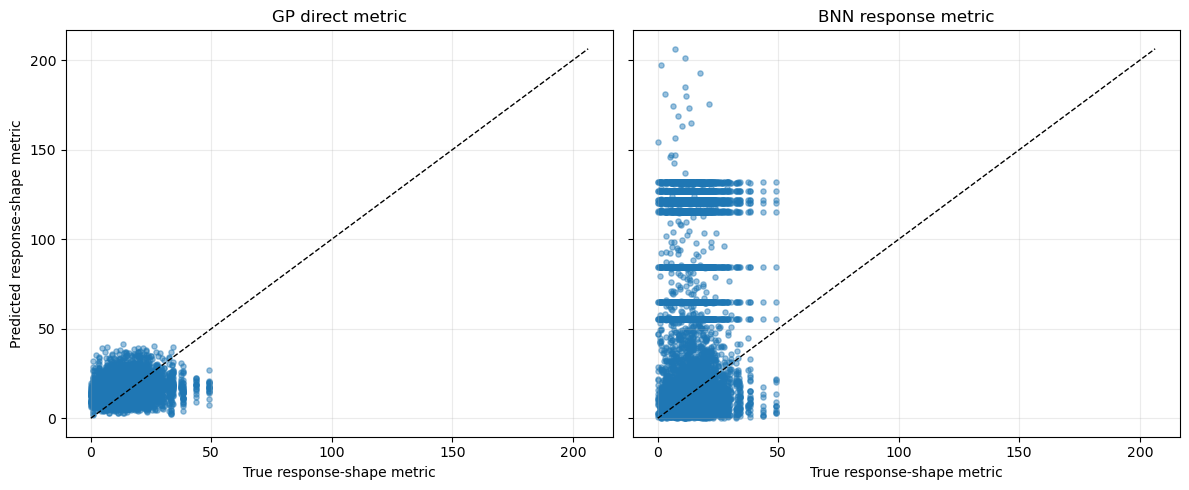

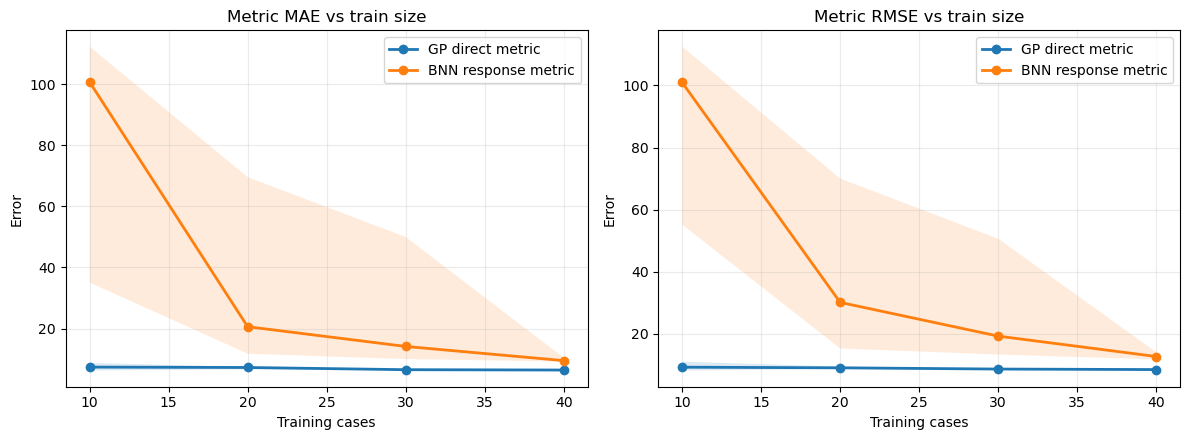

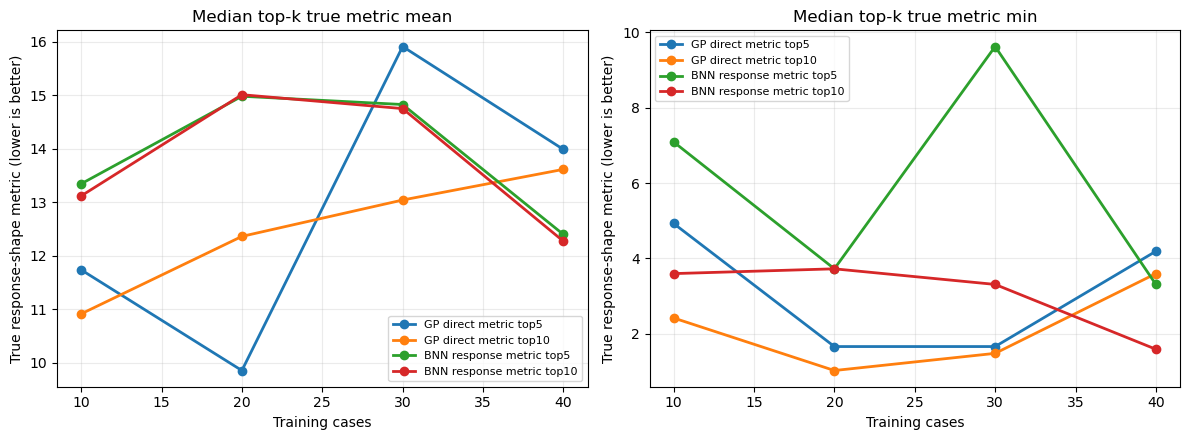

In [7]:
if prediction_df.empty:
    print('No data available for plotting.')
else:
    ok = prediction_df.copy()
    methods = [('gp_direct_metric', 'GP direct metric'), ('bnn_response_metric', 'BNN response metric')]

    fig, axes = plt.subplots(1, len(methods), figsize=(6 * len(methods), 5), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    lo = float(min(ok['true_metric'].min(), ok['pred_metric'].min()))
    hi = float(max(ok['true_metric'].max(), ok['pred_metric'].max()))
    for ax, (method, label) in zip(axes, methods):
        mdf = ok[ok['method'] == method]
        ax.scatter(mdf['true_metric'], mdf['pred_metric'], s=14, alpha=0.45)
        ax.plot([lo, hi], [lo, hi], color='black', linewidth=1.0, linestyle='--')
        ax.set_title(label)
        ax.set_xlabel('True response-shape metric')
        ax.grid(True, alpha=0.25)
    axes[0].set_ylabel('Predicted response-shape metric')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'predicted_vs_true_metric_scatter.png', dpi=180)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for method, label in methods:
        mdf = summary_df[summary_df['method'] == method]
        for metric_name, ax in [('metric_mae', axes[0]), ('metric_rmse', axes[1])]:
            agg = mdf.groupby('train_size')[metric_name].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(agg.index, agg[0.5], marker='o', linewidth=2.0, label=label)
            ax.fill_between(agg.index, agg[0.25], agg[0.75], alpha=0.15)
    axes[0].set_title('Metric MAE vs train size')
    axes[1].set_title('Metric RMSE vs train size')
    for ax in axes:
        ax.set_xlabel('Training cases')
        ax.set_ylabel('Error')
        ax.grid(True, alpha=0.25)
        ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'metric_error_by_train_size.png', dpi=180)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for method, label in methods:
        for k in TOPK_VALUES:
            mdf = topk_summary_df[(topk_summary_df['method'] == method) & (topk_summary_df['k'] == k)]
            mean_agg = mdf.groupby('train_size')['true_metric_mean'].median()
            min_agg = mdf.groupby('train_size')['true_metric_min'].median()
            axes[0].plot(mean_agg.index, mean_agg.values, marker='o', linewidth=2.0, label=f'{label} top{k}')
            axes[1].plot(min_agg.index, min_agg.values, marker='o', linewidth=2.0, label=f'{label} top{k}')
    axes[0].set_title('Median top-k true metric mean')
    axes[1].set_title('Median top-k true metric min')
    for ax in axes:
        ax.set_xlabel('Training cases')
        ax.set_ylabel('True response-shape metric (lower is better)')
        ax.grid(True, alpha=0.25)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'topk_true_metric_by_train_size.png', dpi=180)
    plt.show()


## BNN Predicted Response Mean And Range

This optional diagnostic plot retrains one BNN split, selects one test case, and overlays the true response with the BNN Monte Carlo mean and range. Frequency bands are shaded so the response-shape metric can be interpreted against the passband and stopband targets.


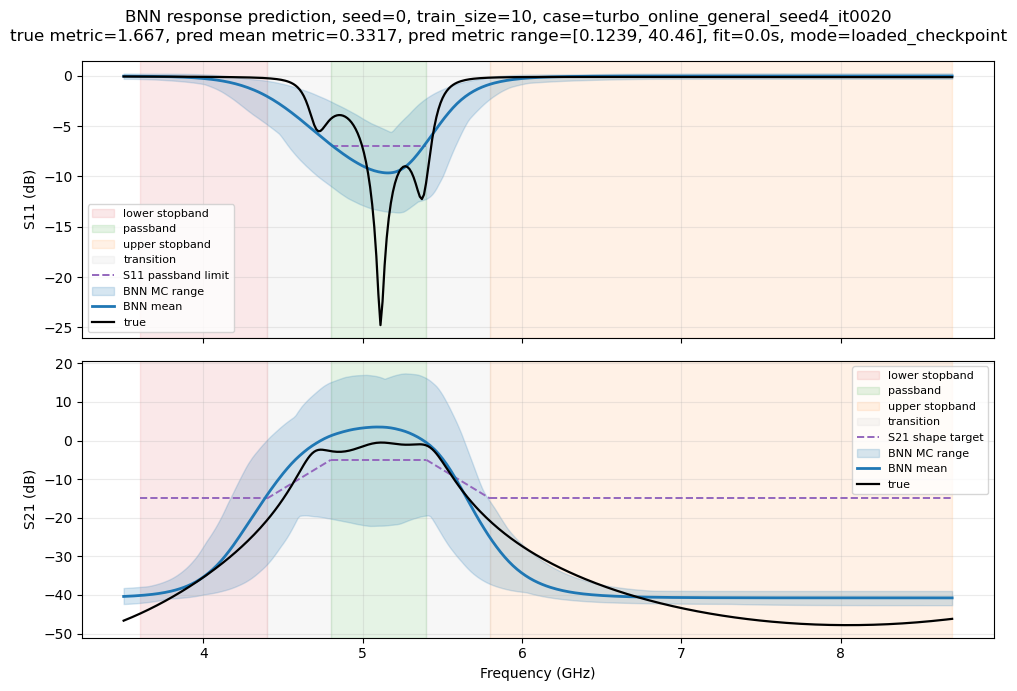

saved response prediction plot: /home/zhanghf/projects/vector/experiments/gp_vs_bnn_response_shape_metric/bnn_response_prediction_seed0_n10_idx129.png


In [8]:
PLOT_RESPONSE_EXAMPLE = True
RESPONSE_PLOT_SEED = SEEDS[0]
RESPONSE_PLOT_TRAIN_SIZE = TRAIN_SIZES[0]
RESPONSE_PLOT_DATASET_INDEX = None  # None selects the BNN-predicted best test case.


def sparam_db_values(sparams: np.ndarray, row: int, col: int) -> np.ndarray:
    mag = np.maximum(np.abs(np.asarray(sparams)[..., row, col, :]), 1e-12)
    return 20.0 * np.log10(mag)


def add_band_hints(ax) -> None:
    lower_stop = SPEC_KWARGS['lower_stopband_ghz']
    passband = SPEC_KWARGS['passband_ghz']
    upper_stop = SPEC_KWARGS['upper_stopband_ghz']
    ax.axvspan(lower_stop[0], lower_stop[1], color='tab:red', alpha=0.10, label='lower stopband')
    ax.axvspan(passband[0], passband[1], color='tab:green', alpha=0.12, label='passband')
    ax.axvspan(upper_stop[0], upper_stop[1], color='tab:orange', alpha=0.10, label='upper stopband')
    if lower_stop[1] < passband[0]:
        ax.axvspan(lower_stop[1], passband[0], color='0.5', alpha=0.06, label='transition')
    if passband[1] < upper_stop[0]:
        ax.axvspan(passband[1], upper_stop[0], color='0.5', alpha=0.06)



def plot_response_shape_target(ax, channel_name: str) -> None:
    lower_stop = SPEC_KWARGS['lower_stopband_ghz']
    passband = SPEC_KWARGS['passband_ghz']
    upper_stop = SPEC_KWARGS['upper_stopband_ghz']
    min_s21 = float(SPEC_KWARGS['min_passband_s21_db'])
    max_s11 = float(SPEC_KWARGS['max_passband_s11_db'])
    max_stop_s21 = float(SPEC_KWARGS['max_stopband_s21_db'])
    if channel_name == 'S11':
        ax.hlines(max_s11, passband[0], passband[1], color='tab:purple', linestyle='--', linewidth=1.4, label='S11 passband limit')
        return
    if channel_name == 'S21':
        ax.hlines(max_stop_s21, lower_stop[0], lower_stop[1], color='tab:purple', linestyle='--', linewidth=1.4, label='S21 shape target')
        ax.plot([lower_stop[1], passband[0]], [max_stop_s21, min_s21], color='tab:purple', linestyle='--', linewidth=1.4)
        ax.hlines(min_s21, passband[0], passband[1], color='tab:purple', linestyle='--', linewidth=1.4)
        ax.plot([passband[1], upper_stop[0]], [min_s21, max_stop_s21], color='tab:purple', linestyle='--', linewidth=1.4)
        ax.hlines(max_stop_s21, upper_stop[0], upper_stop[1], color='tab:purple', linestyle='--', linewidth=1.4)

def metric_for_sparams(sparams: np.ndarray) -> float:
    return float(spec.evaluate(dataset.freqs, sparams).scalar_objective())


def train_bnn_response_prediction(seed: int, train_size: int):
    train_idx, test_idx = make_split(seed, train_size)
    model, fit_seconds, runtime_info = train_or_load_bnn_model(seed, train_size, train_idx)
    mean_sparams, sample_sparams = model.predict_s_params(
        dataset,
        test_idx,
        mc_samples=BNN_KWARGS.get('mc_samples'),
        return_samples=True,
    )
    pred_metric = evaluate_predicted_sparams(test_idx, mean_sparams)
    return train_idx, test_idx, mean_sparams, sample_sparams, pred_metric, fit_seconds, runtime_info


def plot_bnn_response_prediction_with_bands(
    *,
    seed: int,
    train_size: int,
    dataset_index: int | None = None,
) -> Path:
    train_idx, test_idx, mean_sparams, sample_sparams, pred_metric, fit_seconds, runtime_info = train_bnn_response_prediction(seed, train_size)
    if dataset_index is None:
        selected_pos = int(np.argmin(pred_metric))
    else:
        matches = np.where(test_idx == int(dataset_index))[0]
        if len(matches) == 0:
            raise ValueError(f'dataset_index={dataset_index} is not in this split test set')
        selected_pos = int(matches[0])

    idx = int(test_idx[selected_pos])
    freq_ghz = dataset.freqs / 1e9
    true_sparams = dataset.s_params[idx]
    mean_case = mean_sparams[selected_pos]
    samples_case = sample_sparams[:, selected_pos]

    true_metric = metric_for_sparams(true_sparams)
    pred_metric_mean = metric_for_sparams(mean_case)
    sample_metrics = np.asarray([metric_for_sparams(samples_case[i]) for i in range(samples_case.shape[0])], dtype=float)

    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    channel_specs = [('S11', 0, 0), ('S21', 1, 0)]
    for ax, (name, row, col) in zip(axes, channel_specs):
        true_db = sparam_db_values(true_sparams.reshape(1, 2, 2, -1), row, col).reshape(-1)
        mean_db = sparam_db_values(mean_case.reshape(1, 2, 2, -1), row, col).reshape(-1)
        sample_db = sparam_db_values(samples_case, row, col)
        lo_db = np.min(sample_db, axis=0)
        hi_db = np.max(sample_db, axis=0)

        add_band_hints(ax)
        plot_response_shape_target(ax, name)
        ax.fill_between(freq_ghz, lo_db, hi_db, color='tab:blue', alpha=0.18, label='BNN MC range')
        ax.plot(freq_ghz, mean_db, color='tab:blue', linewidth=2.0, label='BNN mean')
        ax.plot(freq_ghz, true_db, color='black', linewidth=1.6, label='true')
        ax.set_ylabel(f'{name} (dB)')
        ax.grid(True, alpha=0.25)
        handles, labels = ax.get_legend_handles_labels()
        unique = dict(zip(labels, handles))
        ax.legend(unique.values(), unique.keys(), fontsize=8, loc='best')

    axes[-1].set_xlabel('Frequency (GHz)')
    fig.suptitle(
        f"BNN response prediction, seed={seed}, train_size={train_size}, case={case_ids[idx]}\n"
        f"true metric={true_metric:.4g}, pred mean metric={pred_metric_mean:.4g}, "
        f"pred metric range=[{float(np.min(sample_metrics)):.4g}, {float(np.max(sample_metrics)):.4g}], "
        f"fit={fit_seconds:.1f}s, mode={runtime_info.get('fit_mode')}"
    )
    fig.tight_layout()
    output_path = OUTPUT_DIR / f'bnn_response_prediction_seed{seed}_n{train_size}_idx{idx}.png'
    fig.savefig(output_path, dpi=180)
    plt.show()
    return output_path


if PLOT_RESPONSE_EXAMPLE:
    saved_path = plot_bnn_response_prediction_with_bands(
        seed=RESPONSE_PLOT_SEED,
        train_size=RESPONSE_PLOT_TRAIN_SIZE,
        dataset_index=RESPONSE_PLOT_DATASET_INDEX,
    )
    print('saved response prediction plot:', saved_path)
else:
    print('PLOT_RESPONSE_EXAMPLE=False; set it to True to train one BNN split and save a response mean/range plot.')
